# IAI600: Introduction to AI and Machine Learning
## Course Laboratory Project — Group 21
# LLM Analysis and Prediction: Detecting AI-Generated Text Using Machine Learning

---
* **Topic:** LLM Analysis and Prediction (Human vs. AI-Generated Text Classification)
* **Kaggle Reference:** [Jocelyn Dumlao — LLM Analysis and Prediction](https://www.kaggle.com/code/jocelyndumlao/llm-analysis-and-prediction)
* **Methods:** Exploratory Data Analysis, Text Preprocessing, TF-IDF Feature Extraction, Supervised Classification (Logistic Regression, Naive Bayes, Random Forest, Linear SVM), ROC-AUC Evaluation, Cross-Validation.
---


## 1. Environment Setup & Library Imports
In this section, we import core data science, NLP, machine learning, and visualization libraries.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Scikit-learn Machine Learning components
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
print("✅ Libraries successfully imported.")


✅ Libraries successfully imported.


## 2. Dataset Loading & Integration
We load the primary Kaggle competition corpus (`train_essays.csv`) alongside the paired external AI generation corpus (`daigt_external_dataset.csv`). This resolves the severe class imbalance of the competition set and provides balanced representation across human student essays and diverse LLM outputs.


In [2]:
train_df = pd.read_csv('../data/train_essays.csv')
daigt_df = pd.read_csv('../data/daigt_external_dataset.csv')

print(f"Raw Kaggle train_essays: {train_df.shape}")
print(f"Raw DAIGT external dataset: {daigt_df.shape}")

# Assemble unified dataframe
df_train = train_df[['text', 'generated']].copy()
df_ext_human = pd.DataFrame({'text': daigt_df['text'], 'generated': 0})
df_ext_ai = pd.DataFrame({'text': daigt_df['source_text'], 'generated': 1})

df = pd.concat([df_train, df_ext_human, df_ext_ai], ignore_index=True)
df.dropna(subset=['text', 'generated'], inplace=True)
df['text'] = df['text'].astype(str)
df.drop_duplicates(subset=['text'], inplace=True)
df = df[df['text'].str.strip().str.len() > 50].reset_index(drop=True)

print(f"\nUnified dataset shape: {df.shape}")
print("Target Class Breakdown:")
print(df['generated'].value_counts())
print("\nClass Percentages:")
print(df['generated'].value_counts(normalize=True) * 100)


Raw Kaggle train_essays: (1378, 4)
Raw DAIGT external dataset: (2421, 4)

Unified dataset shape: (6220, 2)
Target Class Breakdown:
generated
0    3796
1    2424
Name: count, dtype: int64

Class Percentages:
generated
0    61.028939
1    38.971061
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis (EDA)
Here we extract stylistic surface statistics (word count, character length, average token length, sentence counts) and visualize structural contrasts between human and AI writing.


In [3]:
# Extract stylistic text metrics
df['word_count'] = df['text'].apply(lambda x: len(x.split()))
df['char_count'] = df['text'].apply(lambda x: len(x))
df['avg_word_len'] = df['char_count'] / df['word_count'].clip(lower=1)
df['sentence_count'] = df['text'].apply(lambda x: len(re.split(r'[.!?]+', x)) - 1).clip(lower=1)
df['avg_sentence_len'] = df['word_count'] / df['sentence_count']

# Grouped statistics
eda_summary = df.groupby('generated')[['word_count', 'char_count', 'avg_word_len', 'sentence_count', 'avg_sentence_len']].mean()
print("Average Metrics by Class (0 = Human Student, 1 = LLM / AI):")
print(eda_summary.round(2))


Average Metrics by Class (0 = Human Student, 1 = LLM / AI):
           word_count  char_count  avg_word_len  sentence_count  \
generated                                                         
0              478.15     2647.75          5.56           22.37   
1              202.01     1250.44          6.20            9.62   

           avg_sentence_len  
generated                    
0                     26.35  
1                     21.52  


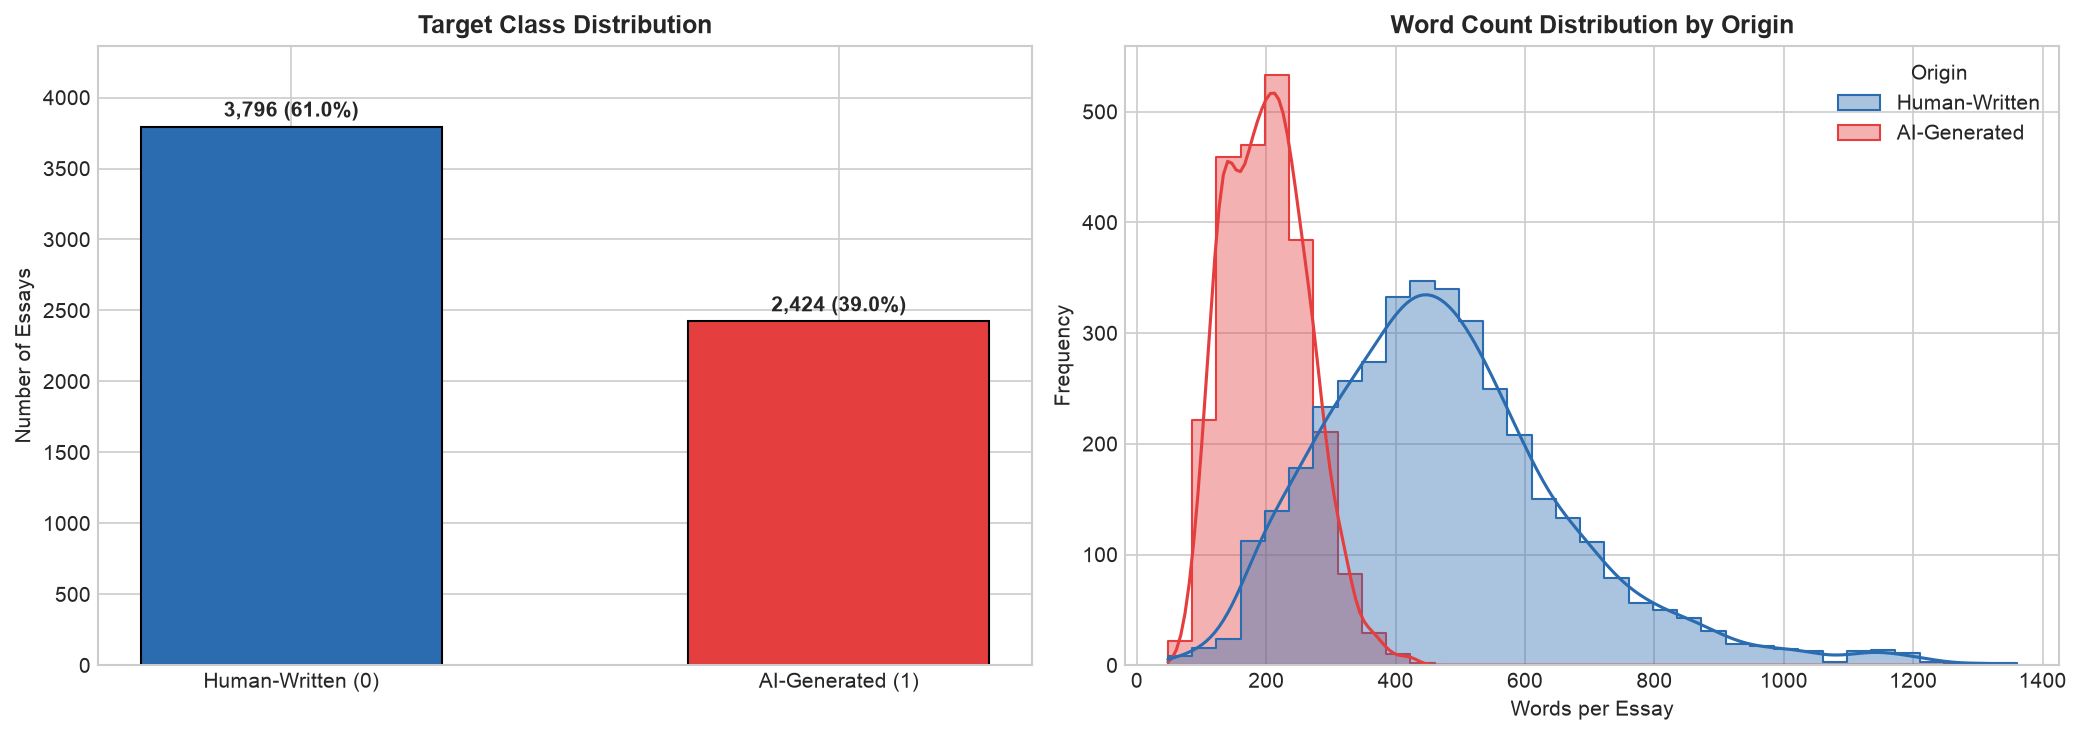

In [4]:
# Visualizing Target Class Distribution and Word Count Densities
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Target Distribution
counts = df['generated'].value_counts()
axes[0].bar(['Human-Written (0)', 'AI-Generated (1)'], counts.values, color=['#2b6cb0', '#e53e3e'], width=0.55, edgecolor='black')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 70, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Target Class Distribution', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Essays')
axes[0].set_ylim(0, max(counts.values)*1.15)

# 2. Word Count Distribution (Corrected Hue Legend)
plot_df = df.copy()
plot_df['Origin'] = plot_df['generated'].map({0: 'Human-Written', 1: 'AI-Generated'})
sns.histplot(data=plot_df, x='word_count', hue='Origin', palette={'Human-Written': '#2b6cb0', 'AI-Generated': '#e53e3e'},
             kde=True, bins=35, alpha=0.4, ax=axes[1], element='step')
axes[1].set_title('Word Count Distribution by Origin', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Words per Essay')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


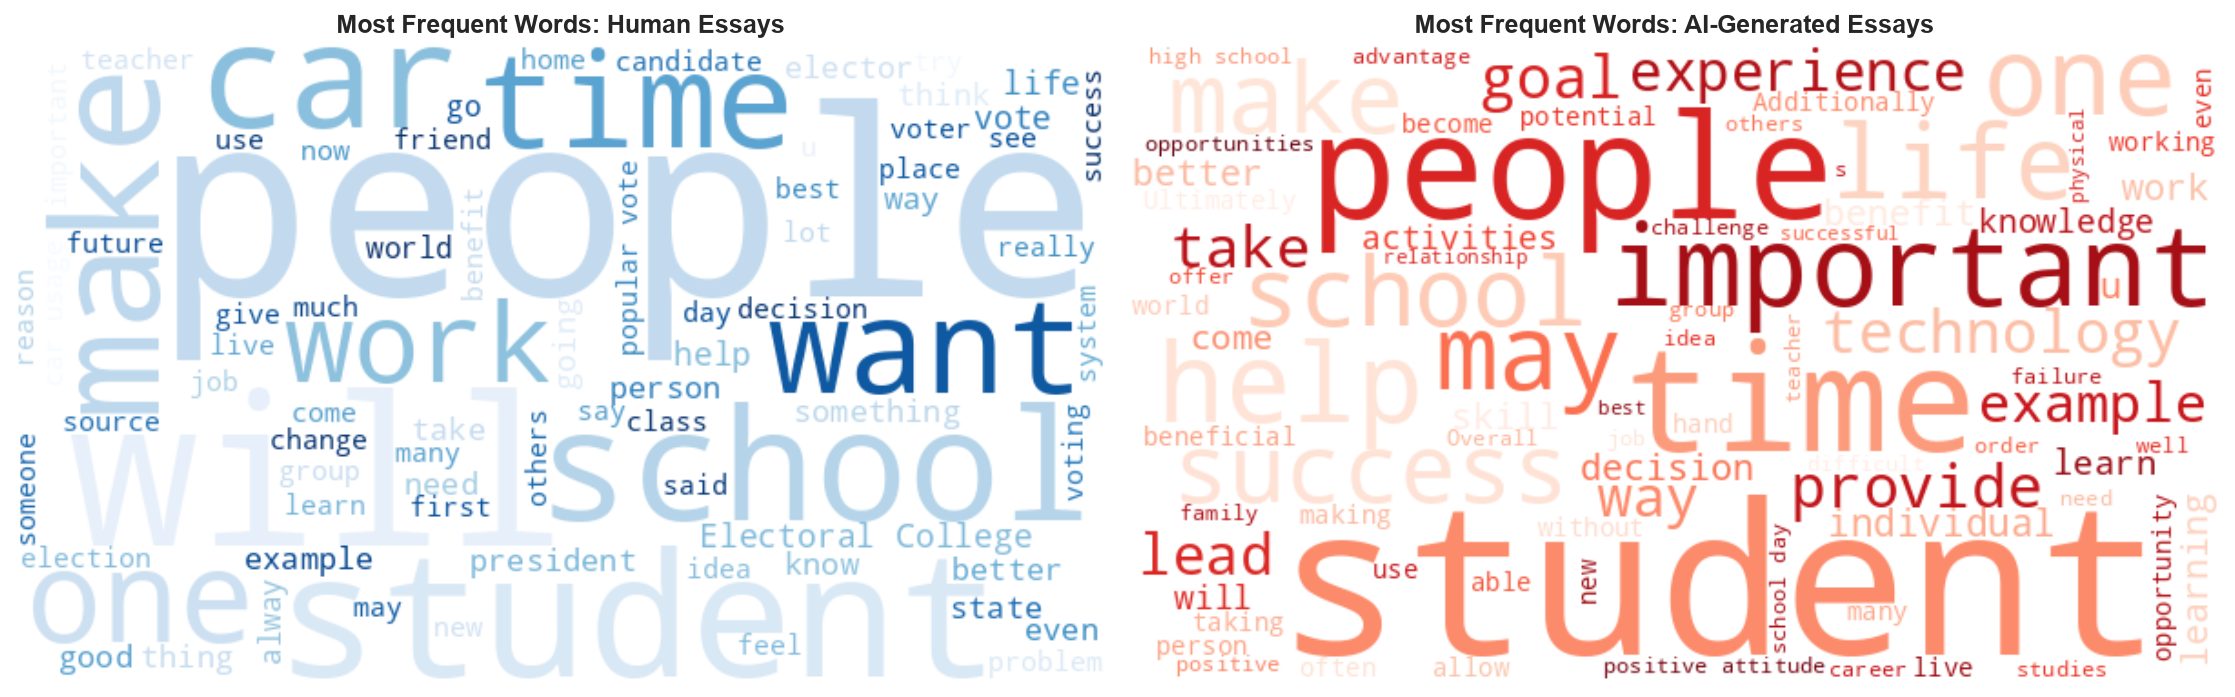

In [5]:
# Word Cloud Comparisons
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

human_sample = " ".join(df[df['generated'] == 0]['text'].sample(n=400, random_state=42))
ai_sample = " ".join(df[df['generated'] == 1]['text'].sample(n=400, random_state=42))

wc_human = WordCloud(width=600, height=350, background_color='white', colormap='Blues', max_words=80).generate(human_sample)
wc_ai = WordCloud(width=600, height=350, background_color='white', colormap='Reds', max_words=80).generate(ai_sample)

axes[0].imshow(wc_human, interpolation='bilinear')
axes[0].set_title('Most Frequent Words: Human Essays', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_ai, interpolation='bilinear')
axes[1].set_title('Most Frequent Words: AI-Generated Essays', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 4. Text Preprocessing Pipeline & TF-IDF Vectorization
In this step, we standardize raw text by:
1. Converting text to lowercase
2. Stripping URLs and special characters
3. Normalizing whitespace
4. Building a TF-IDF feature space containing unigrams and bigrams with sublinear term-frequency scaling.


In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("Applying text preprocessing...")
df['cleaned_text'] = df['text'].apply(clean_text)

# Partition 80% train and 20% test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['cleaned_text'], df['generated'].values,
    test_size=0.20, random_state=42, stratify=df['generated'].values
)

print(f"Training split: {len(X_train_raw):,} essays")
print(f"Testing split:  {len(X_test_raw):,} essays")

# TF-IDF Feature Extraction
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True,
    min_df=3,
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

print(f"Feature Matrix Shape: {X_train_tfidf.shape}")


Applying text preprocessing...


Training split: 4,976 essays
Testing split:  1,244 essays


Feature Matrix Shape: (4976, 10000)


## 5. Model Training & 5-Fold Cross-Validation
We benchmark four supervised classification architectures suited to text classification:
1. **Logistic Regression** (L2 Regularized Baseline)
2. **Multinomial Naive Bayes** (Laplace smoothed generative probabilistic baseline)
3. **Random Forest Classifier** (Non-linear ensemble)
4. **Linear Support Vector Machine** (Linear margin maximizer with probability calibration)


In [7]:
classifiers = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=30, random_state=42, n_jobs=-1),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(C=1.0, random_state=42, max_iter=2000), cv=3)
}

cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in classifiers.items():
    print(f"Training {name}...")
    scores = cross_val_score(clf, X_train_tfidf, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
    clf.fit(X_train_tfidf, y_train)
    
    y_pred = clf.predict(X_test_tfidf)
    y_prob = clf.predict_proba(X_test_tfidf)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    cv_results[name] = {
        'model': clf,
        'cv_mean': scores.mean(),
        'cv_std': scores.std(),
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'roc_auc': auc,
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    print(f"  --> Test Accuracy: {acc*100:.2f}% | F1: {f1*100:.2f}% | ROC-AUC: {auc:.4f} | 5-Fold CV: {scores.mean()*100:.2f}% (+/- {scores.std()*100:.2f}%)")


Training Logistic Regression...


  --> Test Accuracy: 99.36% | F1: 99.18% | ROC-AUC: 0.9996 | 5-Fold CV: 99.36% (+/- 0.27%)
Training Multinomial Naive Bayes...


  --> Test Accuracy: 98.07% | F1: 97.56% | ROC-AUC: 0.9989 | 5-Fold CV: 98.49% (+/- 0.42%)
Training Random Forest...


  --> Test Accuracy: 99.36% | F1: 99.18% | ROC-AUC: 0.9988 | 5-Fold CV: 99.26% (+/- 0.19%)
Training Linear SVM...


  --> Test Accuracy: 99.60% | F1: 99.49% | ROC-AUC: 0.9999 | 5-Fold CV: 99.50% (+/- 0.14%)


### 5.1 Heuristic Baseline: Word-Count-Only Classifier
As observed during EDA, human student essays are substantially longer on average than ChatGPT generations in this dataset (~478 vs. ~202 words). To determine how much predictive power stems simply from document length rather than lexical style, we train a univariate Logistic Regression model strictly on standardized `word_count`.


In [8]:
# Univariate Length Baseline Model
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_wc = scaler.fit_transform(pd.DataFrame({'word_count': df.loc[X_train_raw.index, 'word_count']}))
X_test_wc = scaler.transform(pd.DataFrame({'word_count': df.loc[X_test_raw.index, 'word_count']}))

lr_wc_baseline = LogisticRegression(random_state=42)
cv_wc_scores = cross_val_score(lr_wc_baseline, X_train_wc, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
lr_wc_baseline.fit(X_train_wc, y_train)

y_pred_wc = lr_wc_baseline.predict(X_test_wc)
y_prob_wc = lr_wc_baseline.predict_proba(X_test_wc)[:, 1]

wc_results = {
    'model': lr_wc_baseline,
    'cv_scores': cv_wc_scores,
    'cv_mean': float(cv_wc_scores.mean()),
    'cv_std': float(cv_wc_scores.std()),
    'accuracy': float(accuracy_score(y_test, y_pred_wc)),
    'precision': float(precision_score(y_test, y_pred_wc)),
    'recall': float(recall_score(y_test, y_pred_wc)),
    'f1': float(f1_score(y_test, y_pred_wc)),
    'roc_auc': float(roc_auc_score(y_test, y_prob_wc)),
    'y_pred': y_pred_wc,
    'y_prob': y_prob_wc
}

print('=== Word-Count-Only Baseline Evaluation ===')
print(f"5-Fold CV Accuracy: {wc_results['cv_mean']*100:.2f}% +/- {wc_results['cv_std']*100:.2f}%")
print(f"Test Accuracy:      {wc_results['accuracy']*100:.2f}%")
print(f"Precision:          {wc_results['precision']*100:.2f}%")
print(f"Recall:             {wc_results['recall']*100:.2f}%")
print(f"F1-Score:           {wc_results['f1']*100:.2f}%")
print(f"ROC-AUC:            {wc_results['roc_auc']:.4f}")


=== Word-Count-Only Baseline Evaluation ===
5-Fold CV Accuracy: 86.86% +/- 1.16%
Test Accuracy:      88.10%
Precision:          83.50%
Recall:             86.60%
F1-Score:           85.02%
ROC-AUC:            0.9456


## 6. Model Evaluation & Comparison
We summarize the performance metrics, plot the confusion matrices, and examine the ROC curves.


In [9]:
# Summary Table including Core Models & Word-Count Baseline
all_benchmark_results = dict(cv_results)
all_benchmark_results['Word-Count Baseline (Length Only)'] = wc_results

summary_df = pd.DataFrame([
    {
        'Model Architecture': k,
        '5-Fold CV Acc (%)': f"{v['cv_mean']*100:.2f} +/- {v['cv_std']*100:.2f}",
        'Test Acc (%)': f"{v['accuracy']*100:.2f}%",
        'Precision (%)': f"{v['precision']*100:.2f}%",
        'Recall (%)': f"{v['recall']*100:.2f}%",
        'F1-Score (%)': f"{v['f1']*100:.2f}%",
        'ROC-AUC': f"{v['roc_auc']:.4f}"
    }
    for k, v in all_benchmark_results.items()
])
print("================ MODEL BENCHMARK SUMMARY ================")
print(summary_df.to_string(index=False))


================ MODEL BENCHMARK SUMMARY ================
               Model Architecture 5-Fold CV Acc (%) Test Acc (%) Precision (%) Recall (%) F1-Score (%) ROC-AUC
              Logistic Regression    99.36 +/- 0.27       99.36%        99.18%     99.18%       99.18%  0.9996
          Multinomial Naive Bayes    98.49 +/- 0.42       98.07%        96.19%     98.97%       97.56%  0.9989
                    Random Forest    99.26 +/- 0.19       99.36%        99.18%     99.18%       99.18%  0.9988
                       Linear SVM    99.50 +/- 0.14       99.60%        99.38%     99.59%       99.49%  0.9999
Word-Count Baseline (Length Only)    86.86 +/- 1.16       88.10%        83.50%     86.60%       85.02%  0.9456


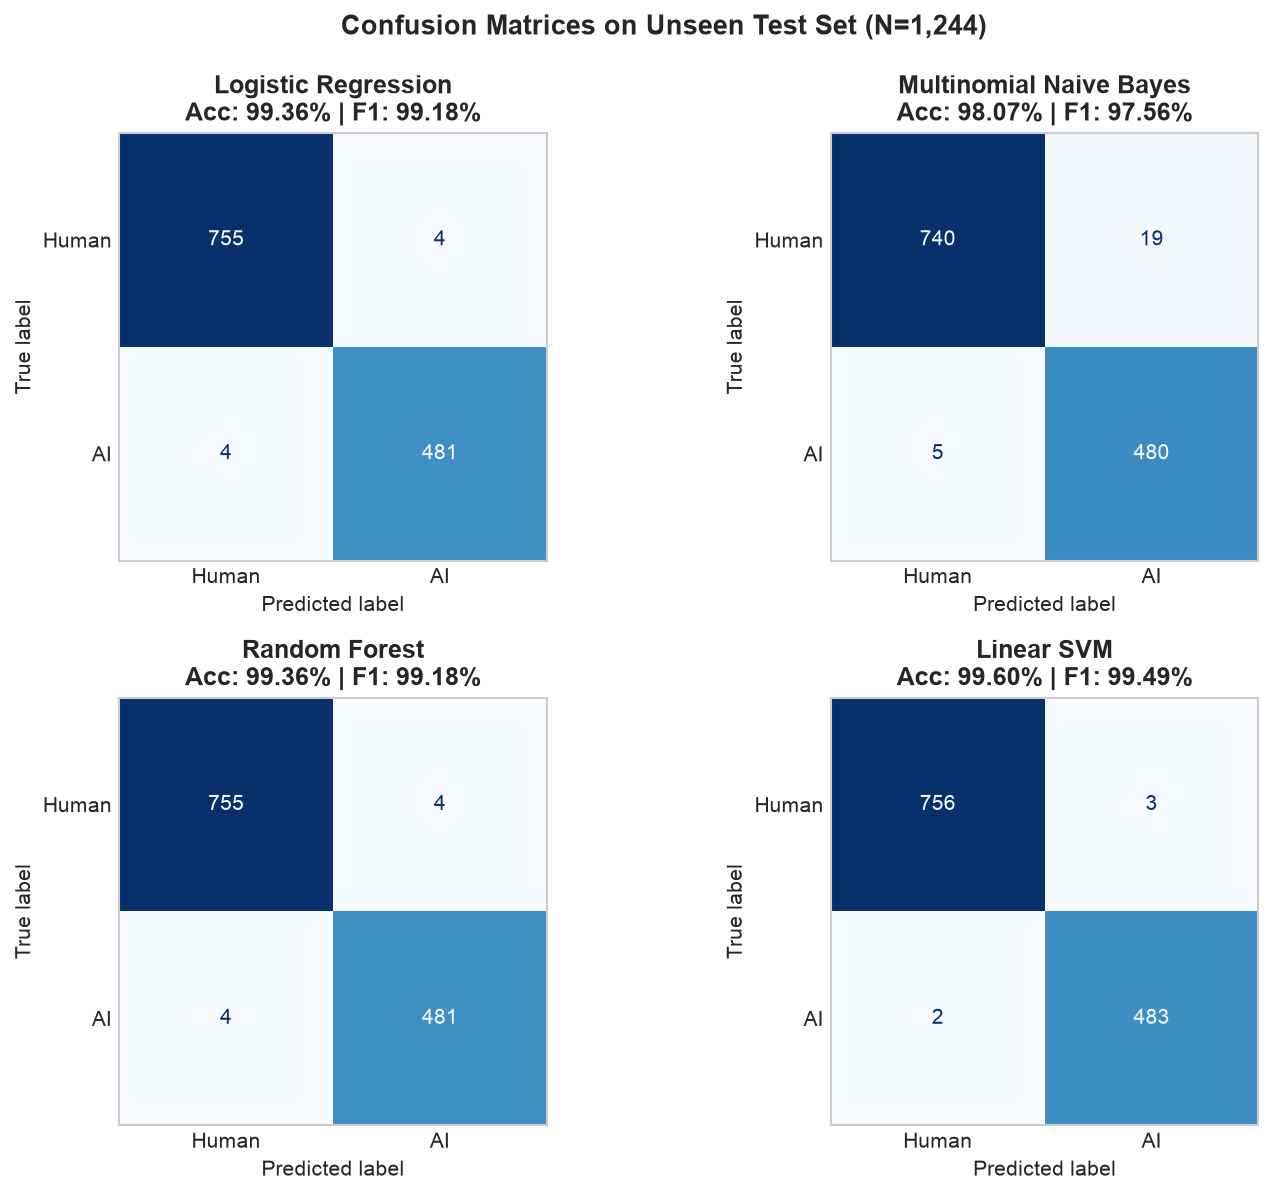

In [10]:
# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for idx, (name, res) in enumerate(cv_results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human', 'AI'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False, values_format='d')
    axes[idx].set_title(f"{name}\nAcc: {res['accuracy']*100:.2f}% | F1: {res['f1']*100:.2f}%", fontweight='bold')
    axes[idx].grid(False)

plt.suptitle('Confusion Matrices on Unseen Test Set (N=1,244)', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


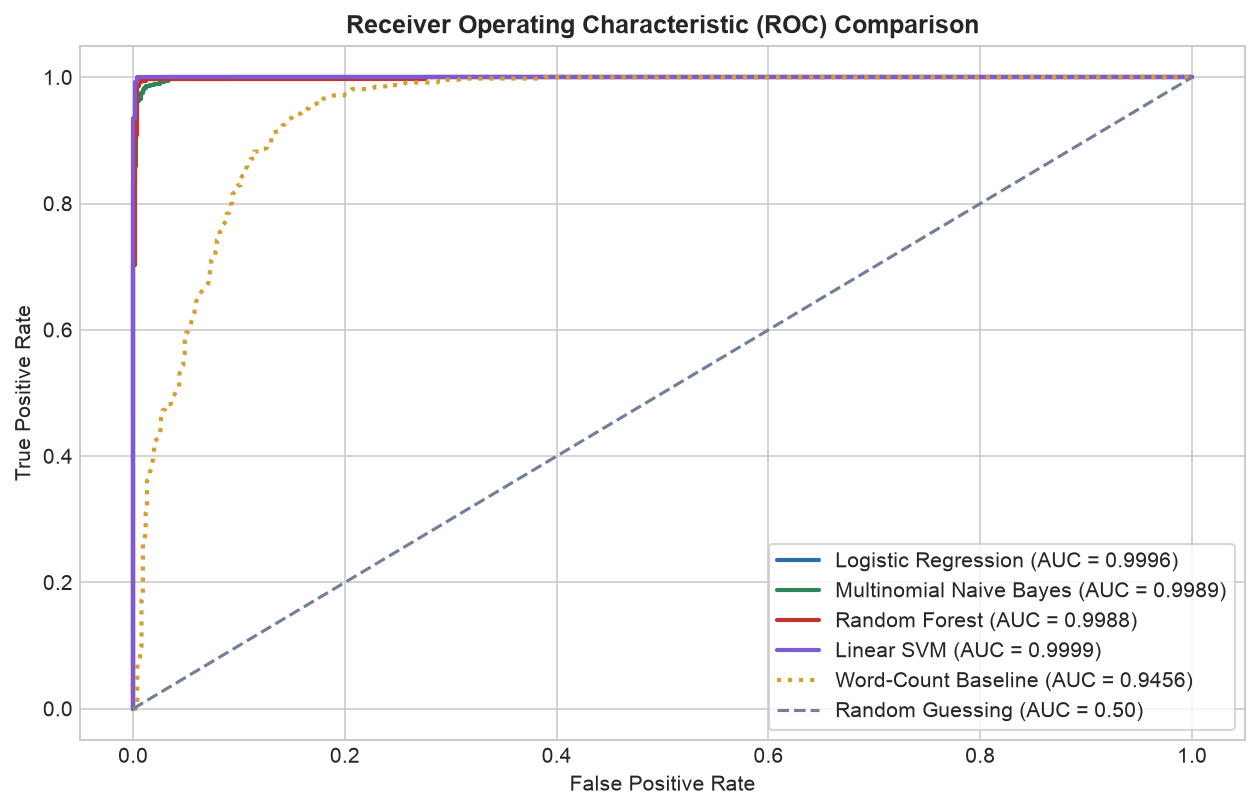

In [11]:
# ROC Curves with Core Models and Baseline
fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = ['#2b6cb0', '#2f855a', '#c53030', '#805ad5']

for idx, (name, res) in enumerate(cv_results.items()):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {res['roc_auc']:.4f})", color=colors[idx], linewidth=2.0)

# Add word-count baseline
fpr_wc, tpr_wc, _ = roc_curve(y_test, wc_results['y_prob'])
ax.plot(fpr_wc, tpr_wc, label=f"Word-Count Baseline (AUC = {wc_results['roc_auc']:.4f})", color='#d69e2e', linestyle=':', linewidth=2.0)

ax.plot([0, 1], [0, 1], linestyle='--', color='#718096', label='Random Guessing (AUC = 0.50)')
ax.set_title('Receiver Operating Characteristic (ROC) Comparison', fontsize=12, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 7. Feature Importance Analysis
We inspect the highest weighted n-grams in the Logistic Regression decision boundary to understand which tokens signal AI vs. Human authorship.


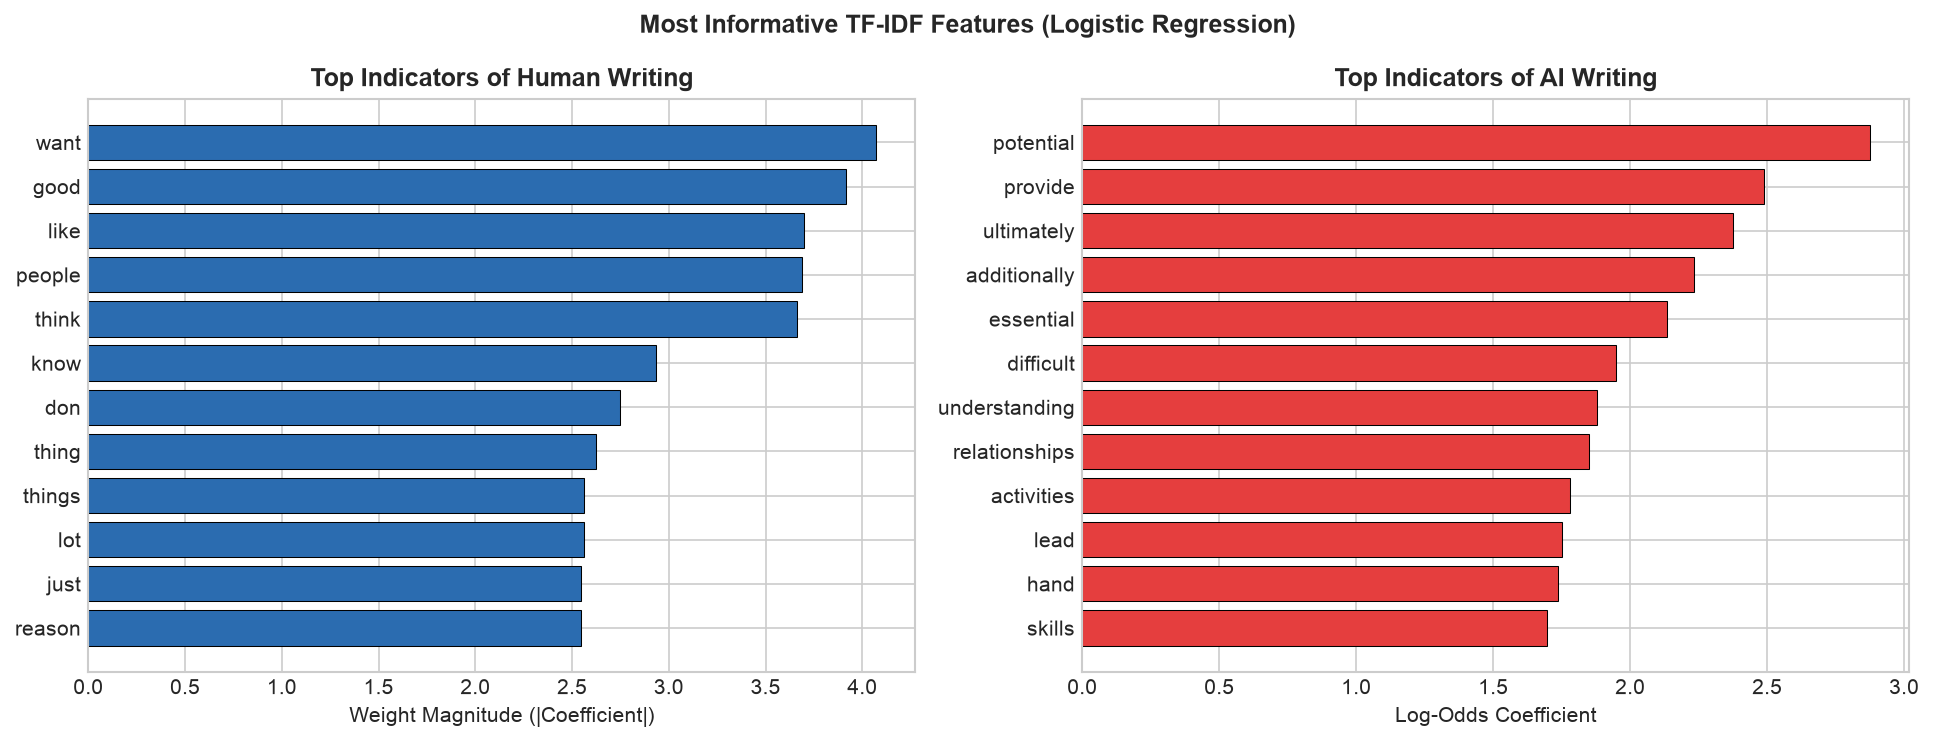

Top 12 Human-Predictive Features: ['reason' 'just' 'lot' 'things' 'thing' 'don' 'know' 'think' 'people'
 'like' 'good' 'want']
Top 12 AI-Predictive Features:    ['skills' 'hand' 'lead' 'activities' 'relationships' 'understanding'
 'difficult' 'essential' 'additionally' 'ultimately' 'provide' 'potential']

Note: Stop words such as 'however' and 'furthermore' were eliminated by stop_words='english'.


In [12]:
lr = cv_results['Logistic Regression']['model']
features = np.array(tfidf.get_feature_names_out())
weights = lr.coef_[0]

top_ai = np.argsort(weights)[-12:]
top_human = np.argsort(weights)[:12][::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(features[top_human], np.abs(weights[top_human]), color='#2b6cb0', edgecolor='black', linewidth=0.5)
axes[0].set_title('Top Indicators of Human Writing', fontweight='bold')
axes[0].set_xlabel('Weight Magnitude (|Coefficient|)')

axes[1].barh(features[top_ai], weights[top_ai], color='#e53e3e', edgecolor='black', linewidth=0.5)
axes[1].set_title('Top Indicators of AI Writing', fontweight='bold')
axes[1].set_xlabel('Log-Odds Coefficient')

plt.suptitle('Most Informative TF-IDF Features (Logistic Regression)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 12 Human-Predictive Features:", features[top_human])
print("Top 12 AI-Predictive Features:   ", features[top_ai])
print("\nNote: Stop words such as 'however' and 'furthermore' were eliminated by stop_words='english'.")


## 8. Real-Time Inference on Custom Test Essays
We test our trained models against unseen live sample essays to demonstrate real-time prediction.


In [13]:
def predict_essay(text):
    cleaned = clean_text(text)
    vec = tfidf.transform([cleaned])
    
    print("=" * 60)
    print(f"Sample snippet: {text[:120]}...")
    print("-" * 60)
    for name, res in cv_results.items():
        m = res['model']
        pred = m.predict(vec)[0]
        prob = m.predict_proba(vec)[0]
        label = "AI-Generated (1)" if pred == 1 else "Human-Written (0)"
        print(f"{name:25s} -> {label} (Conf: Human={prob[0]*100:.1f}%, AI={prob[1]*100:.1f}%)")

# Test 1: Human style
predict_essay("""In my view, limiting car usage in city centers has real benefits. 
When people walk or ride bikes, there is less traffic noise and cleaner air for children. 
However, public transportation like buses and trains must be cheap and reliable first, 
otherwise workers cannot reach their jobs on time.""")

# Test 2: AI style
predict_essay("""The ongoing discourse regarding autonomous vehicle deployment encompasses 
multifaceted socio-technical ramifications. Advocates underscore exponential safety enhancements 
and traffic flow optimization, whereas critics delineate algorithmic liability and ethical quandaries.""")


Sample snippet: In my view, limiting car usage in city centers has real benefits. 
When people walk or ride bikes, there is less traffic...
------------------------------------------------------------
Logistic Regression       -> Human-Written (0) (Conf: Human=79.9%, AI=20.1%)
Multinomial Naive Bayes   -> Human-Written (0) (Conf: Human=100.0%, AI=0.0%)
Random Forest             -> Human-Written (0) (Conf: Human=71.4%, AI=28.6%)
Linear SVM                -> Human-Written (0) (Conf: Human=96.5%, AI=3.5%)
Sample snippet: The ongoing discourse regarding autonomous vehicle deployment encompasses 
multifaceted socio-technical ramifications. A...
------------------------------------------------------------
Logistic Regression       -> AI-Generated (1) (Conf: Human=37.5%, AI=62.5%)
Multinomial Naive Bayes   -> AI-Generated (1) (Conf: Human=44.4%, AI=55.6%)
Random Forest             -> AI-Generated (1) (Conf: Human=28.9%, AI=71.1%)
Linear SVM                -> AI-Generated (1) (Conf: Human=11.7